# Data Preprocessing 

####  1| Import Necessary libs

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import plotly.express as px
from sklearn.feature_extraction.text import TfidfVectorizer,CountVectorizer
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.layers import Embedding,GRU,LSTM,Bidirectional,SimpleRNN
from tensorflow.keras.utils import pad_sequences
from sklearn.preprocessing import LabelEncoder
from keras.models import Sequential
from keras.layers import Dense,Dropout
import tensorflow as tf

import warnings

warnings.filterwarnings('ignore')

#### 2| Loading our data

In [2]:
df = pd.read_csv(r"C:\Users\USER\Ola_Adv_phishing\Data\raw\Phishing_Email.csv")

df.head()

,Unnamed: 0,Email Text,Email Type
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,1,the other side of * galicismos * * galicismo *...,Safe Email
2,2,re : equistar deal tickets are you still avail...,Safe Email
3,3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,4,software at incredibly low prices ( 86 % lower...,Phishing Email


### 3| Text Preprocessing

In [3]:
df.isnull().sum()

Unnamed: 0     0
Email Text    16
Email Type     0
dtype: int64

** There are 16 rows available that have null values .Let's remove these rows



### 3.1| Drop duplicates and null values

In [4]:
df.drop(["Unnamed: 0"],axis=1,inplace=True)
df.dropna(inplace=True,axis=0)
df.drop_duplicates(inplace=True)

In [5]:
print("Dimension of the row data:",df.shape)

Dimension of the row data: (17538, 2)


In [6]:
df.head()

,Email Text,Email Type
0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,the other side of * galicismos * * galicismo *...,Safe Email
2,re : equistar deal tickets are you still avail...,Safe Email
3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,software at incredibly low prices ( 86 % lower...,Phishing Email


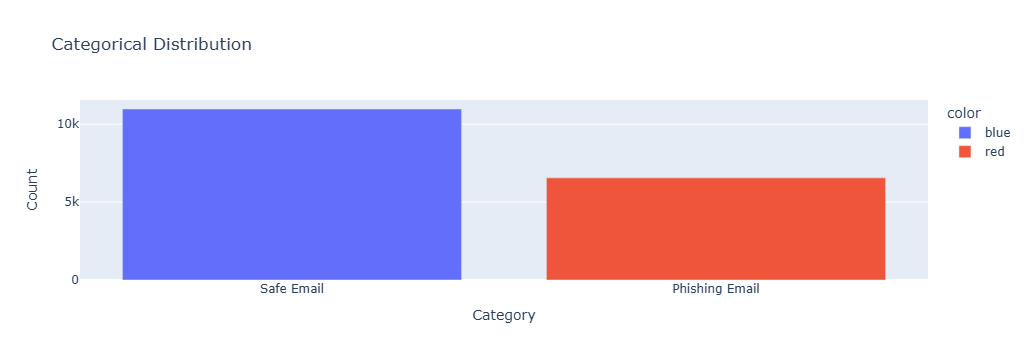

In [7]:
# Create the bar chart
fig = px.bar(df['Email Type'].value_counts(), x=df['Email Type'].value_counts().index, y=df['Email Type'].value_counts().values,
             color=['blue', 'red'], labels={'x': 'Category', 'y': 'Count'},
             title="Categorical Distribution")

# Show the plot
fig.show()

Insigths :

The count of the safe emails is more than that of phishing email so if we see any emails that look like phishing delete

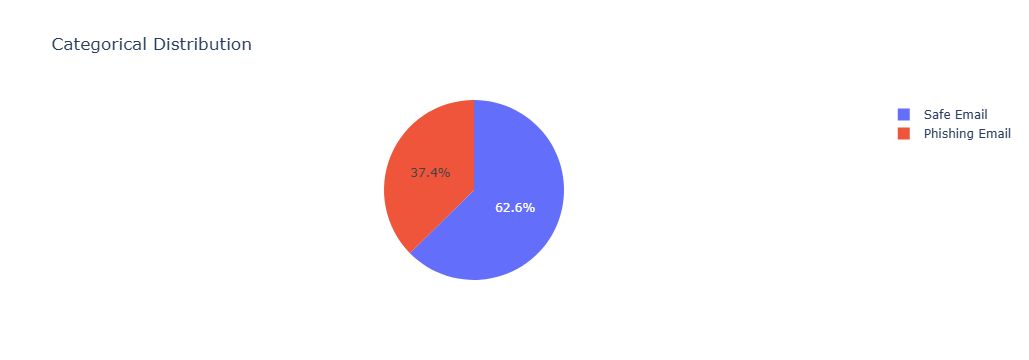

In [8]:
# Create the pie chart
fig_pie = px.pie(df['Email Type'].value_counts(), names=df['Email Type'].value_counts().index,
                 values=df['Email Type'].value_counts().values, title="Categorical Distribution")

# Show the pie chart
fig_pie.show()

### 3.2| Integer Encoding

In [9]:
from sklearn.preprocessing import LabelEncoder


le = LabelEncoder()

df["Email Type"] = le.fit_transform(df["Email Type"])

In [12]:
df

,Email Text,Email Type
0,re 6 1100 disc uniformitarianism re 1086 sex l...,1
1,the other side of galicismos galicismo is a sp...,1
2,re equistar deal tickets are you still availab...,1
3,hello i am your hot lil horny toy i am the one...,0
4,software at incredibly low prices 86 lower dra...,0
...,...,...
18644,rick moen a ãcrit im confused i thought it was...,1
18645,date a lonely housewife always wanted to date ...,0
18646,request submitted access request for anita dup...,1
18647,re important prc mtg hi dorn john as you disco...,1


### 3.3 Remove hyperlinks, punctuations, extra space

In [13]:
import re

def preprocess_text(text):
    # Remove hyperlinks
    text = re.sub(r'http\S+', '', text)

    # Remove punctuations
    text = re.sub(r'[^\w\s]', '', text)

    # Convert to lowercase
    text = text.lower()

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text


# Apply the preprocess_text function to the specified column in the DataFrame
df["Email Text"] =df["Email Text"].apply(preprocess_text)

In [14]:
df.head()

,Email Text,Email Type
0,re 6 1100 disc uniformitarianism re 1086 sex l...,1
1,the other side of galicismos galicismo is a sp...,1
2,re equistar deal tickets are you still availab...,1
3,hello i am your hot lil horny toy i am the one...,0
4,software at incredibly low prices 86 lower dra...,0


# WordCloud

## wordcloud of avaiable stopwords

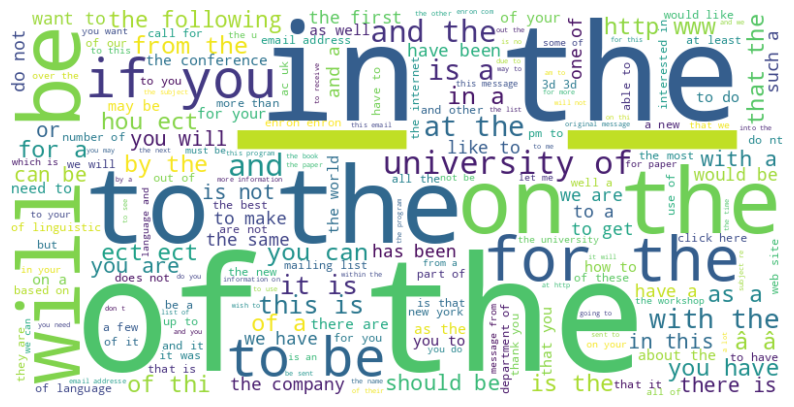

In [15]:
from wordcloud import WordCloud

#combine all rows into a single string
all_mails = " ".join(df['Email Text'])

#create a wordcloud object
word_cloud = WordCloud(stopwords="english",width=800,height=400,background_color='white').generate(all_mails)

plt.figure(figsize=(10,6))
plt.imshow(word_cloud,interpolation='bilinear')
plt.axis("off")
plt.show()

## wordcloude of unique words

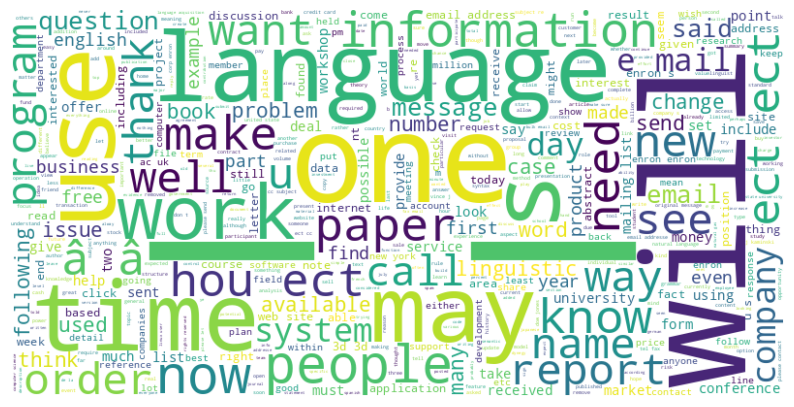

In [16]:
#combine all rows into a single string
all_mails = " ".join(df['Email Text'])

#create a wordcloud object
word_cloud = WordCloud(width=800,height=400,background_color='white',max_words=10000).generate(all_mails)
plt.figure(figsize=(10,6))
plt.imshow(word_cloud,interpolation='bilinear')
plt.axis("off")
plt.show()

### 3.4| Tokenization and Sequence Length Analysis

This section tokenizes the email text into sequences of integers using Keras' `Tokenizer` and analyzes the distribution of sequence lengths after tokenization. Tokenization converts words to numerical indices, preparing the data for neural network models. We visualize the sequence length distribution to understand the variability in email lengths post-tokenization, which helps in setting an appropriate `max_len` for padding.


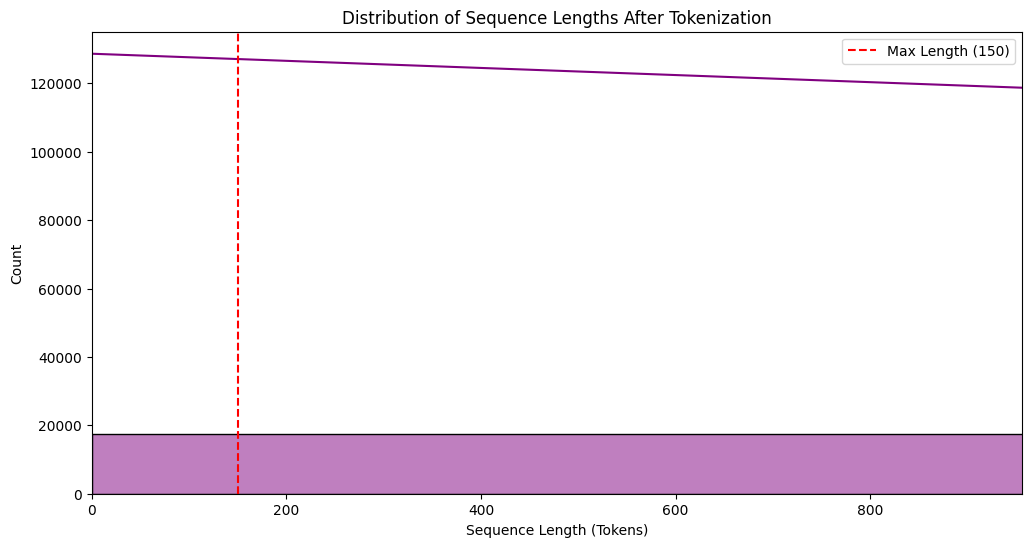

In [17]:

from tensorflow.keras.preprocessing.text import Tokenizer
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Initialize and fit tokenizer
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df['Email Text'])

# Convert text to sequences
sequences = tokenizer.texts_to_sequences(df['Email Text'])

# Calculate sequence lengths
sequence_lengths = [len(seq) for seq in sequences]

# Plot sequence length distribution
plt.figure(figsize=(12, 6))
sns.histplot(sequence_lengths, bins=50, kde=True, color='purple')
plt.title('Distribution of Sequence Lengths After Tokenization')
plt.xlabel('Sequence Length (Tokens)')
plt.ylabel('Count')
plt.xlim(0, np.quantile(sequence_lengths, 0.95))  # Limit x-axis to 95th percentile
plt.axvline(x=150, color='red', linestyle='--', label='Max Length (150)')
plt.legend()
plt.show()

### 4| Feature Transformation with TF-IDF and Dimensionality Visualization

This section applies TF-IDF vectorization to transform the email text into numerical features, as done in the original notebook, but includes a visualization of the resulting feature matrix's sparsity and dimensionality. We use a heatmap to show a subset of the TF-IDF matrix and a bar plot to display the number of non-zero elements per email, highlighting the sparsity of the feature space.


In [18]:

from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


tfidf_matrix = tf.fit_transform(df["Email Text"])  # sparse, memory-efficient

# Calculate non-zero counts directly
non_zero_counts = np.diff(tfidf_matrix.indptr)  # much faster for sparse


AttributeError: module 'tensorflow' has no attribute 'fit_transform'

In [ ]:

# Plot distribution of non-zero elements
plt.figure(figsize=(12, 6))
sns.histplot(non_zero_counts, bins=50, color='green')
plt.title('Distribution of Non-Zero TF-IDF Features per Email')
plt.xlabel('Number of Non-Zero Features')
plt.ylabel('Count')
plt.show()

# Visualize a subset of the TF-IDF matrix as a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(feature_x[:50, :50], cmap='viridis', cbar=True)
plt.title('Heatmap of TF-IDF Feature Matrix (First 50 Emails x 50 Features)')
plt.xlabel('Feature Index')
plt.ylabel('Email Index')
plt.show()

In [ ]:
y_tf = np.array(df['Email Type']) # convert the label into numpy array

### 4.2 Splitting into train and test

In [20]:
# Tokenize
max_len = 150
tk = Tokenizer()
tk.fit_on_texts(df['Email Text'])  # must be called before using tk.word_index
sequences = tk.texts_to_sequences(df['Email Text'])
vector = pad_sequences(sequences, padding='post', maxlen=max_len)

# Vocabulary size (add 1 for padding token 0)
vocab_size = len(tk.word_index) + 1
print("Vocab size:", vocab_size)

# Encode labels
from sklearn.preprocessing import LabelEncoder
label_enc = LabelEncoder()
y_encoded = label_enc.fit_transform(df["Email Type"])

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(
    vector, y_encoded, test_size=0.2, random_state=0
)


Vocab size: 182305


## 5.1| LSTM Architecture

In [21]:
from tensorflow.keras.utils import to_categorical

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

model = Sequential()
model.add(Embedding(input_dim=vocab_size, output_dim=50, input_length=max_len))
model.add(Bidirectional(LSTM(units=64)))
model.add(Dense(32, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))


In [22]:
model.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=1e-3), metrics=['accuracy'])


In [23]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [24]:
historical = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=16,
    validation_data=(x_test, y_test),
    verbose=1
)

Epoch 1/5
877/877 ━━━━━━━━━━━━━━━━━━━━ 163s 180ms/step - accuracy: 0.9126 - loss: 0.2218 - val_accuracy: 0.9684 - val_loss: 0.0944
Epoch 2/5
877/877 ━━━━━━━━━━━━━━━━━━━━ 152s 173ms/step - accuracy: 0.9879 - loss: 0.0422 - val_accuracy: 0.9681 - val_loss: 0.1027
Epoch 3/5
877/877 ━━━━━━━━━━━━━━━━━━━━ 147s 167ms/step - accuracy: 0.9953 - loss: 0.0177 - val_accuracy: 0.9729 - val_loss: 0.0905
Epoch 4/5
877/877 ━━━━━━━━━━━━━━━━━━━━ 144s 165ms/step - accuracy: 0.9954 - loss: 0.0184 - val_accuracy: 0.9704 - val_loss: 0.1038
Epoch 5/5
877/877 ━━━━━━━━━━━━━━━━━━━━ 145s 166ms/step - accuracy: 0.9974 - loss: 0.0087 - val_accuracy: 0.9778 - val_loss: 0.1045


# 7| Performance

In [25]:
results = model.evaluate(x_test, y_test)
loss = results[0]  # Extract the loss from the results
accuracy = results[1]  # Extract the accuracy from the results

print(f"Model Loss: {loss}")
print(f"Model Accuracy: {accuracy*100}")

110/110 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.9778 - loss: 0.1045
Model Loss: 0.10451342165470123
Model Accuracy: 97.77650833129883


In [26]:
y_pred_prob = model.predict(x_test)
y_pred = (y_pred_prob > 0.5).astype(int)

110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step


Text(0, 0.5, 'Loss')

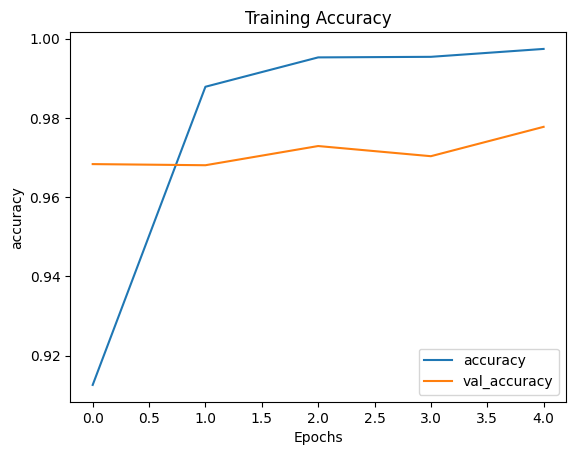

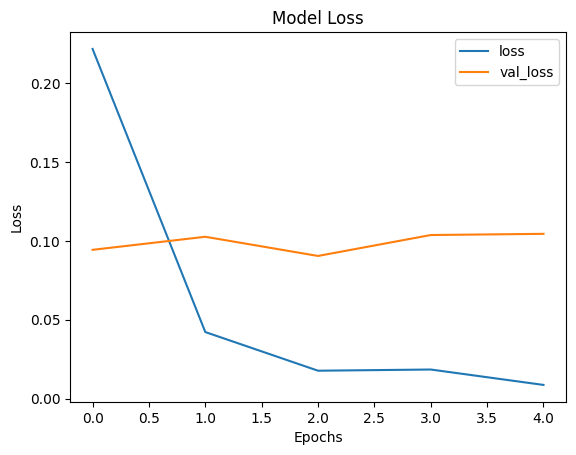

In [27]:
pd.DataFrame(historical.history)

pd.DataFrame(historical.history)[['accuracy', 'val_accuracy']].plot()
plt.title('Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('accuracy')

pd.DataFrame(historical.history)[['loss', 'val_loss']].plot()
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Predictions
y_pred_prob = model.predict(x_test)
y_pred = (y_pred_prob > 0.5).astype(int)

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

# Detailed report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


110/110 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step
Accuracy: 0.9778
Precision: 0.9846
Recall: 0.9791
F1 Score: 0.9819

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.98      0.97      1351
           1       0.98      0.98      0.98      2157

    accuracy                           0.98      3508
   macro avg       0.98      0.98      0.98      3508
weighted avg       0.98      0.98      0.98      3508



# --- Confusion Matrix ---

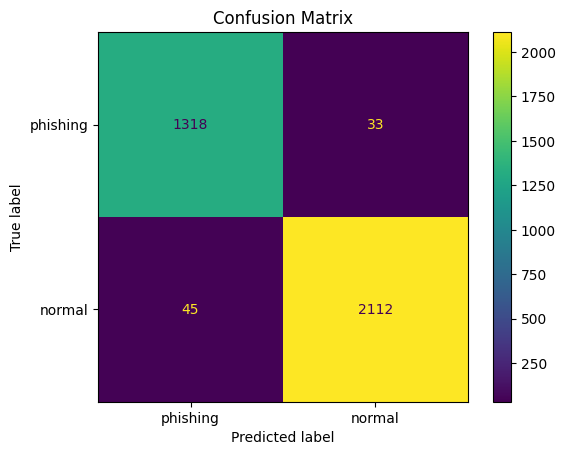

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve



cnf = confusion_matrix(y_test, y_pred)
ax = ConfusionMatrixDisplay(confusion_matrix=cnf, display_labels=['phishing', 'normal'])
ax.plot()
plt.title("Confusion Matrix")
plt.show()


#### AUC-ROC


AUC Score: 0.9964


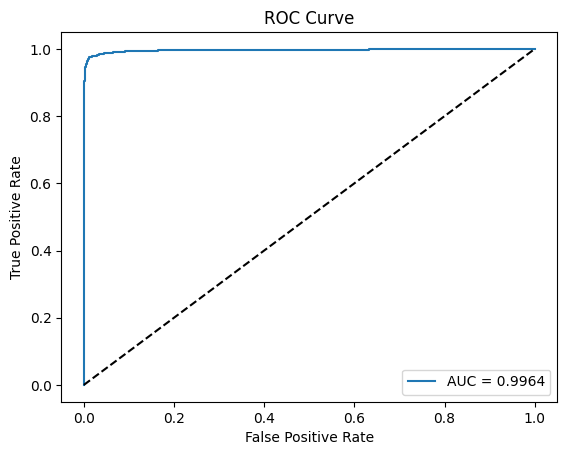

In [30]:
auc_score = roc_auc_score(y_test, y_pred_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

print(f"AUC Score: {auc_score:.4f}")

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.4f}")
plt.plot([0, 1], [0, 1], 'k--')  # Diagonal reference line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

### Save the model after training (from the evalaution, it shows the model is good for its task)

In [31]:

model.save(r"C:\Users\USER\Ola_Adv_phishing\models\lstm_email_classifier.h5")

# To load it later
#from tensorflow.keras.models import load_model
#model = load_model("lstm_email_classifier.h5")
